## Stage 1 Load and Check Data

In [1]:
# Import tools, set the random seed, and prepare the results folder.
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import json
import cProfile
import io
import os
import platform
import pstats
import joblib
import scipy

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_validate
)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from time import perf_counter
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)
from threadpoolctl import threadpool_limits
from pandas.api.types import (
    is_numeric_dtype,
    is_bool_dtype,
    is_complex_dtype
)
from airfoil_prediction import predict_airfoil
SEED = 42

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [2]:
# Locate the raw dataset and check that the file exists.

data_path = Path("data") / "raw" / "airfoil_self_noise.dat"

print("Dataset location:", data_path)
print("File found:", data_path.is_file())

Dataset location: data\raw\airfoil_self_noise.dat
File found: True


In [3]:
# Load the dataset with named columns and inspect the first ten rows.

column_names = [
    "frequency_hz",
    "angle_deg",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m",
    "scaled_spl_db"
]

data = pd.read_csv(
    data_path,
    sep=r"\s+",
    header=None,
    names=column_names
)

print("Dataset shape:", data.shape)

data.head(10)

Dataset shape: (1503, 6)


,frequency_hz,angle_deg,chord_m,velocity_m_s,displacement_thickness_m,scaled_spl_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461
5,2500,0.0,0.3048,71.3,0.002663,125.571
6,3150,0.0,0.3048,71.3,0.002663,125.201
7,4000,0.0,0.3048,71.3,0.002663,123.061
8,5000,0.0,0.3048,71.3,0.002663,121.301
9,6300,0.0,0.3048,71.3,0.002663,119.541


In [4]:
# Define inputs and target, then identify groups with matching operating conditions.

FEATURES = [
    "frequency_hz",
    "angle_deg",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m"
]

TARGET = "scaled_spl_db"

X = data[FEATURES].copy()
y = data[TARGET].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

group_columns = [
    "angle_deg",
    "chord_m",
    "velocity_m_s"
]

groups = X.groupby(
    group_columns,
    sort=True
).ngroup()

print("Number of condition groups:", groups.nunique())

Input shape: (1503, 5)
Target shape: (1503,)
Number of condition groups: 106


In [5]:
# Audit missing values, invalid numbers, physical sign rules, and duplicate rows.

required_columns = FEATURES + [TARGET]

# Convert a separate copy for checking; leave the original data unchanged.
numeric_data = data[required_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# These physical quantities must be greater than zero.
positive_columns = [
    "frequency_hz",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m"
]

# Count missing values and entries that cannot be converted to numbers.
missing_or_text_count = int(
    numeric_data.isna().sum().sum()
)

# Count positive or negative infinity.
infinite_count = int(
    np.isinf(
        numeric_data.to_numpy(dtype=float)
    ).sum()
)

# Count zero or negative entries in quantities that must be positive.
nonpositive_count = int(
    (numeric_data[positive_columns] <= 0).sum().sum()
)

# Count repeated rows across all six dataset columns.
duplicate_count = int(
    data.duplicated().sum()
)

# Collect the checks in a table.
data_audit = pd.DataFrame({
    "check": [
        "Missing or non-numeric entries",
        "Infinite entries",
        "Nonpositive frequency, chord, velocity or thickness",
        "Exact duplicate rows"
    ],
    "count": [
        missing_or_text_count,
        infinite_count,
        nonpositive_count,
        duplicate_count
    ]
})

# Save the audit so the checks are recorded with the project results.
data_audit.to_csv(
    output_dir / "data_audit.csv",
    index=False
)

# Stop this cell if invalid numerical or physical inputs are found.
if (
    missing_or_text_count > 0
    or infinite_count > 0
    or nonpositive_count > 0
):
    raise ValueError(
        "The data audit found invalid entries. "
        "Investigate them before modelling."
    )

# Display the audit table.
data_audit

,check,count
0,Missing or non-numeric entries,0
1,Infinite entries,0
2,"Nonpositive frequency, chord, velocity or thic...",0
3,Exact duplicate rows,0


## Stage 2 Split, explore, and prepare validation

In [6]:
# Separate development and final-test data while keeping condition groups together.

splitter = GroupShuffleSplit(
    n_splits=1,          # Generate one development/test split.
    test_size=0.20,       # Reserve approximately 20% of condition groups.
    random_state=SEED
)

# Obtain the row positions belonging to each subset.
dev_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create the development inputs and targets.
X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()

# Create the final-test inputs and targets.
X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

# Keep the group identifiers aligned with their corresponding rows.
groups_dev = groups.iloc[dev_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("Development rows:", len(X_dev))
print("Final test rows:", len(X_test))

print("Development groups:", groups_dev.nunique())
print("Final test groups:", groups_test.nunique())

Development rows: 1182
Final test rows: 321
Development groups: 84
Final test groups: 22


In [7]:
# Summarise the development data before modelling.

development_data = data.iloc[dev_idx].copy()

development_summary = development_data.describe().T

development_summary

,count,mean,std,min,25%,50%,75%,max
frequency_hz,1182.0,2955.879865,3253.167568,200.000000,800.000000,1600.000000,4000.000000,20000.000000
angle_deg,1182.0,6.896362,6.060298,0.000000,2.000000,5.300000,12.300000,22.200000
chord_m,1182.0,0.131878,0.096196,0.025400,0.050800,0.101600,0.228600,0.304800
velocity_m_s,1182.0,51.520643,15.761609,31.700000,39.600000,55.500000,71.300000,71.300000
displacement_thickness_m,1182.0,0.010968,0.013634,0.000401,0.002663,0.004676,0.013025,0.058411
scaled_spl_db,1182.0,124.924754,6.911733,103.380000,120.244000,125.734000,130.071000,140.987000


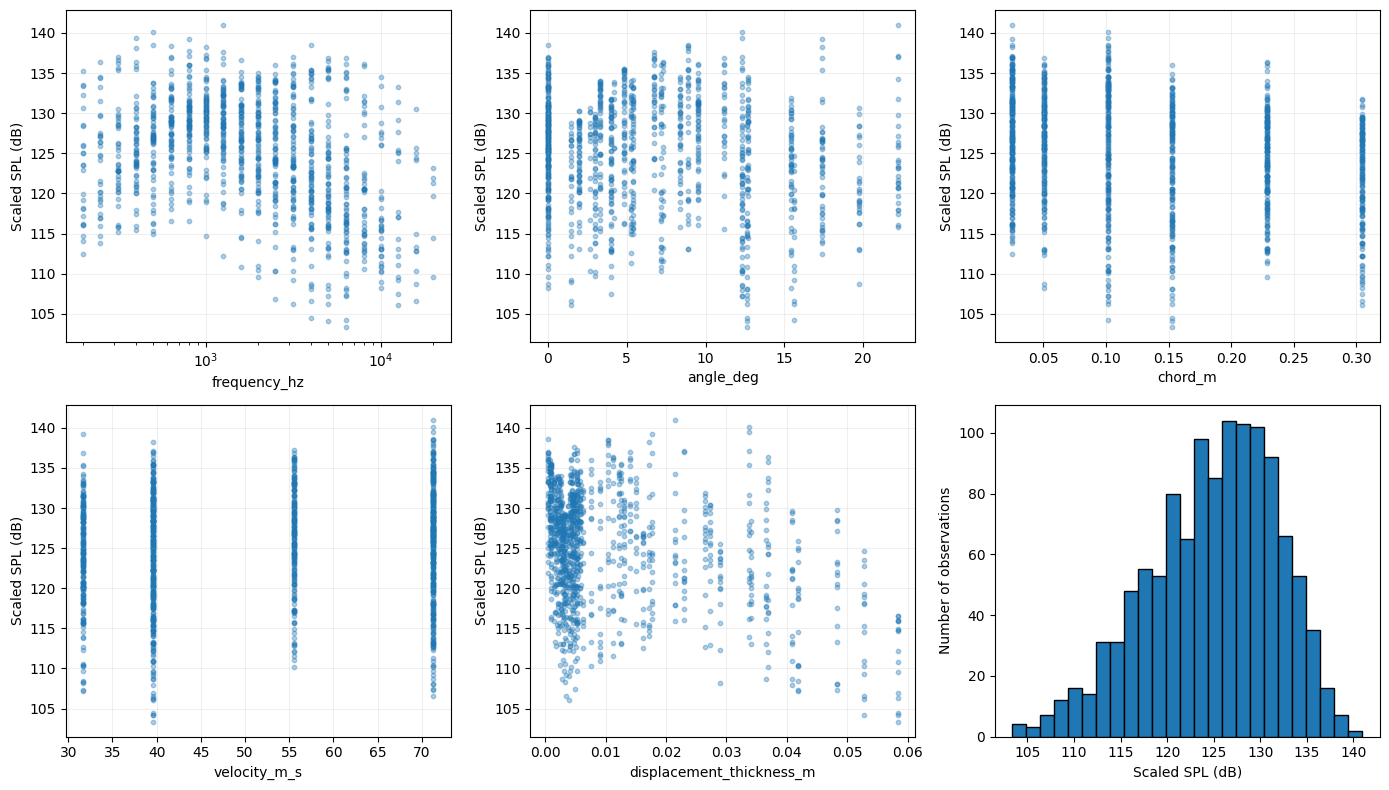

In [8]:
# Plot each input against noise level and show the development target distribution.

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 8)
)

# Convert the subplot arrangement into a one-dimensional collection.
axes = axes.ravel()

# Create one scatter plot for each of the five input features.
for ax, feature in zip(axes, FEATURES):
    ax.scatter(
        X_dev[feature],
        y_dev,
        s=10,
        alpha=0.35
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("Scaled SPL (dB)")
    ax.grid(alpha=0.2)

    # Display frequency on a logarithmic axis.
    if feature == "frequency_hz":
        ax.set_xscale("log")

# Use the sixth subplot for the distribution of measured noise levels.
axes[5].hist(
    y_dev,
    bins=25,
    edgecolor="black"
)

axes[5].set_xlabel("Scaled SPL (dB)")
axes[5].set_ylabel("Number of observations")

# Adjust spacing and save the complete figure.
fig.tight_layout()

fig.savefig(
    output_dir / "development_plots.png",
    dpi=200
)

plt.show()

In [9]:
# Create five grouped validation folds within the development data.

cv = GroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Store the training and validation row positions for each fold.
folds = list(
    cv.split(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

print("Number of folds:", len(folds))

Number of folds: 5


In [10]:
# Verify that condition groups stay separate across development/test and CV splits.

# Check whether any group appears in both development and final-test data.
shared_final_groups = (
    set(groups_dev) & set(groups_test)
)

if shared_final_groups:
    raise ValueError(
        "Some condition groups appear in both development and final test data."
    )

# Collect row counts, group counts, and overlap checks for every CV fold.
fold_check_rows = []

for fold_number, (train_rows, validation_rows) in enumerate(
    folds,
    start=1
):
    training_groups = set(
        groups_dev.iloc[train_rows]
    )

    validation_groups = set(
        groups_dev.iloc[validation_rows]
    )

    # The intersection contains groups appearing on both sides of the fold.
    shared_groups = training_groups & validation_groups

    fold_check_rows.append({
        "fold": fold_number,
        "training_rows": len(train_rows),
        "validation_rows": len(validation_rows),
        "training_groups": len(training_groups),
        "validation_groups": len(validation_groups),
        "shared_groups": len(shared_groups)
    })

fold_checks = pd.DataFrame(fold_check_rows)

# Stop this cell if any fold contains overlapping condition groups.
if (fold_checks["shared_groups"] > 0).any():
    raise ValueError(
        "A validation fold contains groups also used for training."
    )

# Save the verification results.
fold_checks.to_csv(
    output_dir / "group_split_checks.csv",
    index=False
)

print(
    "Groups shared between development and final test:",
    len(shared_final_groups)
)

# Display row counts and group checks for all five folds.
fold_checks

Groups shared between development and final test: 0


,fold,training_rows,validation_rows,training_groups,validation_groups,shared_groups
0,1,947,235,67,17,0
1,2,947,235,67,17,0
2,3,953,229,67,17,0
3,4,934,248,67,17,0
4,5,947,235,68,16,0


1. If Ridge improves on the mean predictor, the inputs contain useful predictive information that a linear model can exploit.
2. If SVR improves further, a nonlinear model is a promising candidate.
3. A much smaller training error than validation error can indicate overfitting or difficulty transferring to excluded conditions.
4. High errors on both training and validation data may suggest an overly restrictive model, limited input information, or noisy observations.

## Stage 3: Compare and interpret baseline models

In [11]:
# Define five initial models for comparison before hyperparameter tuning.

models = {
    # Predict the mean of the targets used for training.
    "Mean": DummyRegressor(strategy="mean"),

    # Fit ordinary least squares without a coefficient penalty.
    "Linear": Pipeline([
        ("scale", StandardScaler()),
        ("model", LinearRegression())
    ]),

    # Fit a linear model with a penalty on large coefficients.
    "Ridge": Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    # Fit SVR using a linear relationship in the supplied features.
    "SVR_linear": Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            SVR(
                kernel="linear",
                C=1.0,
                epsilon=0.1
            )
        )
    ]),

    # Fit SVR using an RBF kernel to represent nonlinear relationships.
    "SVR": Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            SVR(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                epsilon=0.1
            )
        )
    ])
}

In [12]:
# Define a reusable function for evaluating models on the same validation folds.

def evaluate_model(model, features, targets, cv_folds):
    """
    Evaluate a regression model on predefined validation folds.

    Parameters
    ----------
    model : scikit-learn estimator or Pipeline
        Model configuration to evaluate.
    features : pandas.DataFrame
        Numeric input features, with one observation per row.
    targets : pandas.Series
        Measured scaled SPL in dB, aligned with features.
    cv_folds : list of tuples
        Training and validation row positions within features.

    Returns
    -------
    pandas.DataFrame
        One row per fold containing training RMSE, validation RMSE,
        validation MAE, validation R², and fitting time.
        RMSE and MAE are in dB, R² is dimensionless,
        and fitting time is in seconds.
    """

    # Fit and evaluate a fresh model on each supplied fold.
    scores = cross_validate(
        model,
        features,
        targets,
        cv=cv_folds,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    # Convert negative error scores back into positive error values.
    return pd.DataFrame({
        "fold": np.arange(1, len(cv_folds) + 1),
        "train_rmse_db": -scores["train_rmse"],
        "val_rmse_db": -scores["test_rmse"],
        "val_mae_db": -scores["test_mae"],
        "val_r2": scores["test_r2"],
        "fit_time_s": scores["fit_time"]
    })

In [13]:
# Evaluate all baseline models and rank them by grouped validation RMSE.

# Store the detailed results for each model.
cv_tables = {}

# Collect one summary row per model.
comparison_rows = []

for name, model in models.items():
    fold_table = evaluate_model(
        model,
        X_dev,
        y_dev,
        folds
    )

    # Retain the individual fold results for inspection and saving.
    cv_tables[name] = fold_table

    # Summarise performance across the five validation folds.
    comparison_rows.append({
        "model": name,
        "train_rmse_db": fold_table["train_rmse_db"].mean(),
        "cv_rmse_db": fold_table["val_rmse_db"].mean(),
        "fold_rmse_sd_db": fold_table["val_rmse_db"].std(ddof=1),
        "cv_mae_db": fold_table["val_mae_db"].mean(),
        "cv_r2": fold_table["val_r2"].mean(),
        "mean_fit_time_s": fold_table["fit_time_s"].mean()
    })

comparison = pd.DataFrame(comparison_rows)

# Put the model with the lowest mean validation RMSE first.
comparison = comparison.sort_values("cv_rmse_db")

# Round the displayed table while retaining full precision in the stored data.
comparison.round(3)

,model,train_rmse_db,cv_rmse_db,fold_rmse_sd_db,cv_mae_db,cv_r2,mean_fit_time_s
4,SVR,3.772,4.035,0.353,3.049,0.645,0.078
2,Ridge,4.690,4.728,0.413,3.684,0.510,0.011
1,Linear,4.689,4.728,0.413,3.683,0.510,0.010
3,SVR_linear,4.764,4.797,0.413,3.630,0.496,0.076
0,Mean,6.906,6.929,0.401,5.650,-0.020,0.004


In [14]:
# Save baseline results, development statistics, and the exact data split.

# Save the overall baseline comparison.
comparison.to_csv(
    output_dir / "baseline_comparison.csv",
    index=False
)

# Save each model's individual fold results.
for name, fold_table in cv_tables.items():
    fold_table.to_csv(
        output_dir / f"{name.lower()}_cv_folds.csv",
        index=False
    )

# Save the development summary, including its feature-name index.
development_summary.to_csv(
    output_dir / "development_summary.csv"
)

# Record the original row position and condition group for every observation.
split_manifest = pd.DataFrame({
    "row_position": np.arange(len(data)),
    "group_id": groups.to_numpy(),
    "subset": "development"
})

# Label the rows assigned to the reserved final-test dataset.
split_manifest.loc[test_idx, "subset"] = "final_test"

# Save the exact development/test allocation.
split_manifest.to_csv(
    output_dir / "split_manifest.csv",
    index=False
)

# Display Ridge's individual fold results for inspection.
cv_tables["Ridge"]

,fold,train_rmse_db,val_rmse_db,val_mae_db,val_r2,fit_time_s
0,1,4.765120,4.425172,3.550496,0.600499,0.015524
1,2,4.755925,4.465545,3.496765,0.590394,0.008002
2,3,4.768611,4.398523,3.295056,0.649343,0.007003
3,4,4.599143,5.095940,3.992648,0.397998,0.015997
4,5,4.558721,5.254434,4.083975,0.312339,0.008998


In [15]:
# Express the fitted linear model's coefficients in the original input units.

# Fit a separate linear model on all development data for interpretation.
linear_for_interpretation = clone(
    models["Linear"]
).fit(X_dev, y_dev)

# Access the fitted scaler and linear regression model.
linear_scaler = linear_for_interpretation.named_steps["scale"]
linear_regressor = linear_for_interpretation.named_steps["model"]

# Convert coefficients from standardised inputs to the original input units.
coefficients_original_units = (
    linear_regressor.coef_ / linear_scaler.scale_
)

# Adjust the intercept to account for the centring performed by the scaler.
intercept_original_units = float(
    linear_regressor.intercept_
    - np.dot(
        coefficients_original_units,
        linear_scaler.mean_
    )
)

# Collect the intercept, coefficients, and their corresponding units.
linear_coefficient_table = pd.DataFrame({
    "parameter": ["intercept"] + FEATURES,
    "value": [
        intercept_original_units,
        *coefficients_original_units
    ],
    "unit": [
        "dB",
        "dB per Hz",
        "dB per degree",
        "dB per m",
        "dB per (m/s)",
        "dB per m"
    ]
})

# Save the coefficient table for reporting and interpretation.
linear_coefficient_table.to_csv(
    output_dir / "linear_coefficients.csv",
    index=False
)

linear_coefficient_table

,parameter,value,unit
0,intercept,132.621839,dB
1,frequency_hz,-0.001226,dB per Hz
2,angle_deg,-0.397247,dB per degree
3,chord_m,-36.722636,dB per m
4,velocity_m_s,0.102122,dB per (m/s)
5,displacement_thickness_m,-159.833739,dB per m


## Stage 4 Tune the promising models

In [16]:
# Define candidate hyperparameters for Ridge and SVR.

ridge_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

svr_grid = {
    "model__C": [1.0, 10.0, 100.0],
    "model__gamma": ["scale", 0.05, 0.5],
    "model__epsilon": [0.1, 0.5]
}

In [17]:
# Find the Ridge penalty giving the lowest grouped validation RMSE.
ridge_search = GridSearchCV(
    estimator=models["Ridge"],
    param_grid=ridge_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1
)
# Start timing immediately before the search begins.
start_time = perf_counter()
# Evaluate every alpha value across the five grouped folds.
ridge_search.fit(X_dev, y_dev)
# Record elapsed time, including cross-validation and the final refit.
ridge_search_time = perf_counter() - start_time

print("Best Ridge settings:", ridge_search.best_params_)
print(
    "Best Ridge CV RMSE:",
    round(-ridge_search.best_score_, 3),
    "dB"
)
print(
    "Total Ridge search time:",
    round(ridge_search_time, 2),
    "seconds"
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Ridge settings: {'model__alpha': 10.0}
Best Ridge CV RMSE: 4.727 dB
Total Ridge search time: 0.56 seconds


In [18]:
# Find the SVR settings giving the lowest grouped validation RMSE.

svr_search = GridSearchCV(
    estimator=models["SVR"],
    param_grid=svr_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

svr_search.fit(X_dev, y_dev)

svr_search_time = perf_counter() - start_time

print("Best SVR settings:", svr_search.best_params_)
print(
    "Best SVR CV RMSE:",
    round(-svr_search.best_score_, 3),
    "dB"
)
print(
    "Total SVR search time:",
    round(svr_search_time, 2),
    "seconds"
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best SVR settings: {'model__C': 100.0, 'model__epsilon': 0.5, 'model__gamma': 0.5}
Best SVR CV RMSE: 3.477 dB
Total SVR search time: 24.21 seconds


In [19]:
# Compare baseline and tuned validation errors using identical folds.

baseline_rmse = comparison.set_index("model")["cv_rmse_db"]

tuning_summary = pd.DataFrame({
    "model": ["Ridge", "SVR"],

    "baseline_cv_rmse_db": [
        baseline_rmse["Ridge"],
        baseline_rmse["SVR"]
    ],

    "tuned_cv_rmse_db": [
        -ridge_search.best_score_,
        -svr_search.best_score_
    ],

    "search_time_s": [
        ridge_search_time,
        svr_search_time
    ]
})

tuning_summary["rmse_reduction_percent"] = (
    100
    * (
        tuning_summary["baseline_cv_rmse_db"]
        - tuning_summary["tuned_cv_rmse_db"]
    )
    / tuning_summary["baseline_cv_rmse_db"]
)

tuning_summary.round(3)

,model,baseline_cv_rmse_db,tuned_cv_rmse_db,search_time_s,rmse_reduction_percent
0,Ridge,4.728,4.727,0.56,0.013
1,SVR,4.035,3.477,24.21,13.840


In [20]:
# Inspect candidate training and validation errors to understand the search.

ridge_grid_results = pd.DataFrame(ridge_search.cv_results_)
svr_grid_results = pd.DataFrame(svr_search.cv_results_)

for table in [ridge_grid_results, svr_grid_results]:
    table["cv_rmse_db"] = -table["mean_test_score"]
    table["train_rmse_db"] = -table["mean_train_score"]

columns_to_show = [
    "param_model__C",
    "param_model__gamma",
    "param_model__epsilon",
    "train_rmse_db",
    "cv_rmse_db"
]

svr_grid_results.sort_values("cv_rmse_db")[
    columns_to_show
].head(5)

,param_model__C,param_model__gamma,param_model__epsilon,train_rmse_db,cv_rmse_db
17,100.0,0.5,0.5,2.150300,3.476731
11,10.0,0.5,0.5,2.604980,3.483926
14,100.0,0.5,0.1,2.168860,3.499447
8,10.0,0.5,0.1,2.616006,3.513519
9,10.0,scale,0.5,3.128913,3.599727


In [21]:
# Keep the tuned development models and save the search results.

tuned_models = {
    "Ridge": ridge_search.best_estimator_,
    "SVR": svr_search.best_estimator_
}

tuning_summary.to_csv(
    output_dir / "tuning_summary.csv",
    index=False
)

ridge_grid_results.to_csv(
    output_dir / "ridge_grid_search.csv",
    index=False
)

svr_grid_results.to_csv(
    output_dir / "svr_grid_search.csv",
    index=False
)

print("Tuned models available:", list(tuned_models.keys()))
print("Results saved in:", output_dir.resolve())

Tuned models available: ['Ridge', 'SVR']
Results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results


## Stage 5: Investigate preprocessing

In [22]:
# Prepare the preprocessing tools and check that the inputs selected for log10 are positive.
LOG_FEATURES = [
    "frequency_hz",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m",
]

positive_inputs = X_dev[LOG_FEATURES].to_numpy(dtype=float)

if not np.isfinite(positive_inputs).all():
    raise ValueError(
        "The inputs selected for log10 contain missing or infinite values."
    )

if (positive_inputs <= 0).any():
    raise ValueError(
        "Every input selected for log10 must be greater than zero."
    )

print("Development data shape:", X_dev.shape)
print("Number of validation folds:", len(folds))
print("All inputs selected for log10 are finite and positive.")

Development data shape: (1182, 5)
Number of validation folds: 5
All inputs selected for log10 are finite and positive.


In [23]:
# Build pipelines that log selected inputs, scale all five inputs, and fit the model.

log_preprocessor = ColumnTransformer(
    transformers=[
        (
            "log10",
            FunctionTransformer(
                np.log10,
                validate=True,
                feature_names_out="one-to-one",
            ),
            LOG_FEATURES,
        ),
        (
            "angle",
            "passthrough",
            ["angle_deg"],
        ),
    ],
    remainder="drop",
)

log_ridge_pipeline = Pipeline(
    steps=[
        ("transform", clone(log_preprocessor)),
        ("scale", StandardScaler()),
        ("model", Ridge()),
    ]
)

log_svr_pipeline = Pipeline(
    steps=[
        ("transform", clone(log_preprocessor)),
        ("scale", StandardScaler()),
        ("model", SVR(kernel="rbf")),
    ]
)

print("Logarithmic preprocessing pipelines are ready.")

Logarithmic preprocessing pipelines are ready.


In [24]:
# Tune Ridge after log preprocessing using the same grid and validation folds.

log_ridge_search = GridSearchCV(
    estimator=log_ridge_pipeline,
    param_grid=ridge_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

start_time = perf_counter()

log_ridge_search.fit(X_dev, y_dev)

log_ridge_search_time = perf_counter() - start_time

print("Best log-preprocessed Ridge parameters:")
print(log_ridge_search.best_params_)

print(
    "Best log-preprocessed Ridge CV RMSE:",
    f"{-log_ridge_search.best_score_:.3f} dB",
)

print(
    "Log-preprocessed Ridge search time:",
    f"{log_ridge_search_time:.2f} seconds",
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best log-preprocessed Ridge parameters:
{'model__alpha': 10.0}
Best log-preprocessed Ridge CV RMSE: 5.217 dB
Log-preprocessed Ridge search time: 0.72 seconds


In [25]:
# Tune SVR after logarithmic preprocessing using the original grid and validation folds.

log_svr_search = GridSearchCV(
    estimator=log_svr_pipeline,
    param_grid=svr_search.param_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

log_svr_search.fit(X_dev, y_dev)

print("Best log-preprocessed SVR parameters:")
print(log_svr_search.best_params_)

print(
    "Best log-preprocessed SVR CV RMSE:",
    f"{-log_svr_search.best_score_:.3f} dB",
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best log-preprocessed SVR parameters:
{'model__C': 100.0, 'model__epsilon': 0.5, 'model__gamma': 0.05}
Best log-preprocessed SVR CV RMSE: 2.829 dB


In [26]:
# Compare tuned validation RMSE before and after logarithmic preprocessing.

preprocessing_comparison = pd.DataFrame(
    {
        "model": ["Ridge", "SVR"],
        "scaled_cv_rmse_db": [
            -ridge_search.best_score_,
            -svr_search.best_score_,
        ],
        "log_scaled_cv_rmse_db": [
            -log_ridge_search.best_score_,
            -log_svr_search.best_score_,
        ],
    }
)

preprocessing_comparison["rmse_reduction_db"] = (
    preprocessing_comparison["scaled_cv_rmse_db"]
    - preprocessing_comparison["log_scaled_cv_rmse_db"]
)

preprocessing_comparison.round(3)

,model,scaled_cv_rmse_db,log_scaled_cv_rmse_db,rmse_reduction_db
0,Ridge,4.727,5.217,-0.490
1,SVR,3.477,2.829,0.648


In [27]:
# Inspect training and validation errors for the logarithmically preprocessed searches.

log_ridge_results = pd.DataFrame(log_ridge_search.cv_results_)
log_svr_results = pd.DataFrame(log_svr_search.cv_results_)

for table in [log_ridge_results, log_svr_results]:
    table["cv_rmse_db"] = -table["mean_test_score"]
    table["train_rmse_db"] = -table["mean_train_score"]

columns_to_show = [
    "param_model__C",
    "param_model__gamma",
    "param_model__epsilon",
    "train_rmse_db",
    "cv_rmse_db",
]

log_svr_results.sort_values("cv_rmse_db")[columns_to_show].head(5)

,param_model__C,param_model__gamma,param_model__epsilon,train_rmse_db,cv_rmse_db
16,100.0,0.05,0.5,2.360238,2.828992
8,10.0,0.5,0.1,1.533498,2.843152
6,10.0,scale,0.1,2.079920,2.853051
9,10.0,scale,0.5,2.066597,2.853399
11,10.0,0.5,0.5,1.519170,2.855327


In [28]:
# Save the preprocessing evidence and retain all four fitted candidate pipelines.

preprocessing_candidates = {
    "Ridge_scaled": ridge_search.best_estimator_,
    "Ridge_log_scaled": log_ridge_search.best_estimator_,
    "SVR_scaled": svr_search.best_estimator_,
    "SVR_log_scaled": log_svr_search.best_estimator_,
}

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

preprocessing_comparison.to_csv(
    output_dir / "preprocessing_comparison.csv",
    index=False,
)

log_ridge_results.to_csv(
    output_dir / "ridge_log_grid_search.csv",
    index=False,
)

log_svr_results.to_csv(
    output_dir / "svr_log_grid_search.csv",
    index=False,
)

print("Results saved in:", output_dir.resolve())
print("Available candidates:", list(preprocessing_candidates))

Results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results
Available candidates: ['Ridge_scaled', 'Ridge_log_scaled', 'SVR_scaled', 'SVR_log_scaled']


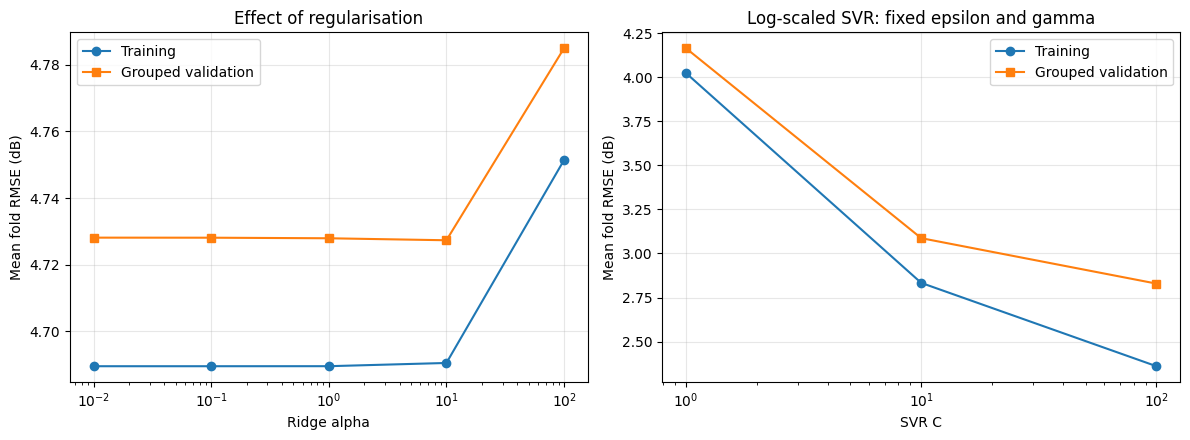

In [29]:
# Examine training and grouped-validation error as model settings change.

ridge_curve = pd.DataFrame(
    ridge_search.cv_results_
)

ridge_curve["alpha"] = pd.to_numeric(
    ridge_curve["param_model__alpha"]
)

ridge_curve["training_rmse_db"] = (
    -ridge_curve["mean_train_score"]
)

ridge_curve["validation_rmse_db"] = (
    -ridge_curve["mean_test_score"]
)

ridge_curve = ridge_curve.sort_values("alpha")

class_svr_results = pd.DataFrame(
    log_svr_search.cv_results_
)

best_log_settings = log_svr_search.best_params_

# Hold epsilon and gamma fixed while examining C.
c_curve = class_svr_results.loc[
    (
        class_svr_results["param_model__epsilon"]
        == best_log_settings["model__epsilon"]
    )
    & (
        class_svr_results["param_model__gamma"]
        == best_log_settings["model__gamma"]
    )
].copy()

c_curve["C"] = pd.to_numeric(
    c_curve["param_model__C"]
)

c_curve["training_rmse_db"] = (
    -c_curve["mean_train_score"]
)

c_curve["validation_rmse_db"] = (
    -c_curve["mean_test_score"]
)

c_curve = c_curve.sort_values("C")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    ridge_curve["alpha"],
    ridge_curve["training_rmse_db"],
    "o-",
    label="Training"
)

axes[0].plot(
    ridge_curve["alpha"],
    ridge_curve["validation_rmse_db"],
    "s-",
    label="Grouped validation"
)

axes[0].set_xlabel("Ridge alpha")
axes[0].set_title("Effect of regularisation")

axes[1].plot(
    c_curve["C"],
    c_curve["training_rmse_db"],
    "o-",
    label="Training"
)

axes[1].plot(
    c_curve["C"],
    c_curve["validation_rmse_db"],
    "s-",
    label="Grouped validation"
)

axes[1].set_xlabel("SVR C")
axes[1].set_title("Log-scaled SVR: fixed epsilon and gamma")

for ax in axes:
    ax.set_xscale("log")
    ax.set_ylabel("Mean fold RMSE (dB)")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()

fig.savefig(
    output_dir / "training_validation_curves.png",
    dpi=200
)

plt.show()

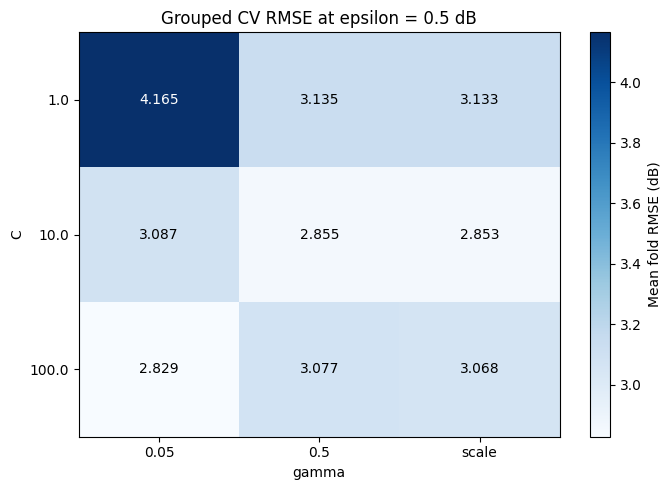

In [30]:
# Compare C and gamma jointly at the selected epsilon using existing CV results.

heatmap_rows = class_svr_results.loc[
    class_svr_results["param_model__epsilon"]
    == best_log_settings["model__epsilon"]
].copy()

heatmap_rows["C"] = pd.to_numeric(
    heatmap_rows["param_model__C"]
)

heatmap_rows["gamma_label"] = (
    heatmap_rows["param_model__gamma"].astype(str)
)

heatmap_rows["cv_rmse_db"] = (
    -heatmap_rows["mean_test_score"]
)

parameter_heatmap = heatmap_rows.pivot(
    index="C",
    columns="gamma_label",
    values="cv_rmse_db"
).sort_index()

fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(
    parameter_heatmap.to_numpy(),
    cmap="Blues",
    aspect="auto"
)

ax.set_xticks(
    np.arange(len(parameter_heatmap.columns)),
    labels=parameter_heatmap.columns
)

ax.set_yticks(
    np.arange(len(parameter_heatmap.index)),
    labels=parameter_heatmap.index
)

colour_boundary = (
    parameter_heatmap.to_numpy().min()
    + parameter_heatmap.to_numpy().max()
) / 2

for row in range(parameter_heatmap.shape[0]):
    for column in range(parameter_heatmap.shape[1]):
        value = parameter_heatmap.iloc[row, column]

        ax.text(
            column,
            row,
            f"{value:.3f}",
            ha="center",
            va="center",
            color="white" if value > colour_boundary else "black"
        )

ax.set_xlabel("gamma")
ax.set_ylabel("C")

ax.set_title(
    "Grouped CV RMSE at "
    f"epsilon = {best_log_settings['model__epsilon']:g} dB"
)

fig.colorbar(
    image,
    ax=ax,
    label="Mean fold RMSE (dB)"
)

fig.tight_layout()

fig.savefig(
    output_dir / "svr_parameter_heatmap.png",
    dpi=200
)

plt.show()

## Stage 6: Model Selection 

In [31]:
# Prepare evaluation tools and confirm that development and test groups do not overlap.

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

overlapping_groups = set(groups_dev).intersection(set(groups_test))

if overlapping_groups:
    raise ValueError(
        "Development and test sets share groups. Check the original split."
    )

print("Development rows:", len(X_dev))
print("Test rows:", len(X_test))
print("Overlapping groups:", len(overlapping_groups))

Development rows: 1182
Test rows: 321
Overlapping groups: 0


In [32]:
# Rank the tuned candidates using their existing mean cross-validation RMSE.
# Our selection rule remains the one used during tuning: choose the lowest mean cross-validation RMSE.

candidate_searches = {
    "Ridge_scaled": ridge_search,
    "Ridge_log_scaled": log_ridge_search,
    "SVR_scaled": svr_search,
    "SVR_log_scaled": log_svr_search,
}

selection_rows = []

for name, search in candidate_searches.items():
    best_index = search.best_index_

    fold_errors = [
        -search.cv_results_[f"split{i}_test_score"][best_index]
        for i in range(len(folds))
    ]

    selection_rows.append(
        {
            "candidate": name,
            "cv_rmse_db": -search.best_score_,
            "fold_rmse_sd_db": np.std(fold_errors, ddof=1),
        }
    )

selection_table = (
    pd.DataFrame(selection_rows)
    .sort_values(["cv_rmse_db", "candidate"])
    .reset_index(drop=True)
)

selection_table.round(3)

,candidate,cv_rmse_db,fold_rmse_sd_db
0,SVR_log_scaled,2.829,0.538
1,SVR_scaled,3.477,0.829
2,Ridge_scaled,4.727,0.412
3,Ridge_log_scaled,5.217,0.535


In [33]:
# Freeze the CV winner and fit a mean baseline before final testing.

selected_name = selection_table.loc[0, "candidate"]
selected_search = candidate_searches[selected_name]

# The search has already refitted its best pipeline on all development rows.
final_model = selected_search.best_estimator_

# Fit the simple reference model on the same development rows.
mean_baseline = DummyRegressor(strategy="mean")
mean_baseline.fit(X_dev, y_dev)

# Record why this model was chosen, before looking at test results.
selection_record = {
    "selected_candidate": selected_name,
    "selection_rule": (
        "Lowest mean grouped cross-validation RMSE on development data"
    ),
    "cv_rmse_db": float(selection_table.loc[0, "cv_rmse_db"]),
    "best_parameters": selected_search.best_params_,
}

with (output_dir / "model_selection.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(selection_record, file, indent=2)

print("Selected candidate:", selected_name)
print("Selected parameters:", selected_search.best_params_)
print(
    "Selection CV RMSE:",
    f"{selection_table.loc[0, 'cv_rmse_db']:.3f} dB",
)

Selected candidate: SVR_log_scaled
Selected parameters: {'model__C': 100.0, 'model__epsilon': 0.5, 'model__gamma': 0.05}
Selection CV RMSE: 2.829 dB


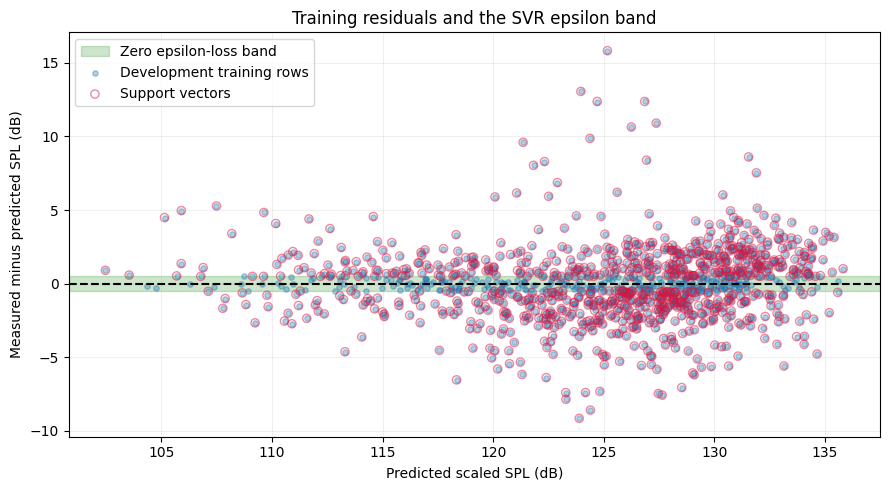

,training_rows,support_vectors,support_fraction,epsilon_db,tube_width_db
0,1182,924,0.782,0.5,1.0


In [34]:
# Inspect support vectors and the epsilon band of the fitted final SVR.

final_svr = final_model.named_steps["model"]

development_predictions = final_model.predict(X_dev)

development_residuals = (
    y_dev.to_numpy() - development_predictions
)

support_mask = np.zeros(
    len(X_dev),
    dtype=bool
)

support_mask[final_svr.support_] = True

epsilon_db = float(final_svr.epsilon)

svr_training_diagnostics = pd.DataFrame({
    "measured_spl_db": y_dev.to_numpy(),
    "predicted_spl_db": development_predictions,
    "residual_db": development_residuals,
    "is_support_vector": support_mask,
    "epsilon_loss_db": np.maximum(
        np.abs(development_residuals) - epsilon_db,
        0.0
    )
}, index=X_dev.index)

support_summary = pd.DataFrame({
    "training_rows": [len(X_dev)],
    "support_vectors": [int(support_mask.sum())],
    "support_fraction": [float(support_mask.mean())],
    "epsilon_db": [epsilon_db],
    "tube_width_db": [2 * epsilon_db]
})

fig, ax = plt.subplots(figsize=(9, 5))

ax.axhspan(
    -epsilon_db,
    epsilon_db,
    alpha=0.2,
    color="green",
    label="Zero epsilon-loss band"
)

ax.scatter(
    development_predictions,
    development_residuals,
    s=15,
    alpha=0.35,
    label="Development training rows"
)

ax.scatter(
    development_predictions[support_mask],
    development_residuals[support_mask],
    s=35,
    facecolors="none",
    edgecolors="crimson",
    alpha=0.5,
    label="Support vectors"
)

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Predicted scaled SPL (dB)")
ax.set_ylabel("Measured minus predicted SPL (dB)")
ax.set_title("Training residuals and the SVR epsilon band")
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

fig.savefig(
    output_dir / "svr_epsilon_and_support_vectors.png",
    dpi=200
)

svr_training_diagnostics.to_csv(
    output_dir / "svr_training_diagnostics.csv",
    index_label="row_index"
)

support_summary.to_csv(
    output_dir / "svr_support_summary.csv",
    index=False
)

plt.show()

support_summary.round(3)

In [35]:
# Evaluate the fixed model and mean baseline using the reserved test observations.

def regression_metrics(actual, predicted):
    """
    Calculate metrics for matching 1D measured and predicted values in dB.

    Returns RMSE, MAE and mean residual in dB, plus dimensionless R-squared.
    Residual is defined as measured minus predicted.
    """
    residuals = np.asarray(actual) - np.asarray(predicted)

    return {
        "rmse_db": root_mean_squared_error(actual, predicted),
        "mae_db": mean_absolute_error(actual, predicted),
        "r2": r2_score(actual, predicted),
        "mean_residual_db": float(np.mean(residuals)),
    }


test_predictions = final_model.predict(X_test)
mean_test_predictions = mean_baseline.predict(X_test)

test_metrics = pd.DataFrame(
    [
        {
            "model": selected_name,
            **regression_metrics(y_test, test_predictions),
        },
        {
            "model": "Mean_baseline",
            **regression_metrics(y_test, mean_test_predictions),
        },
    ]
)

test_metrics.round(3)

,model,rmse_db,mae_db,r2,mean_residual_db
0,SVR_log_scaled,2.410,1.844,0.876,0.042
1,Mean_baseline,6.853,5.610,-0.004,-0.416


In [36]:
# Record each test prediction alongside its operating conditions and error.

test_prediction_table = X_test.copy()

test_prediction_table.insert(
    0,
    "row_index",
    X_test.index.to_numpy(),
)

test_prediction_table["group_id"] = groups_test.to_numpy()
test_prediction_table["measured_spl_db"] = y_test.to_numpy()
test_prediction_table["predicted_spl_db"] = test_predictions

test_prediction_table["residual_db"] = (
    test_prediction_table["measured_spl_db"]
    - test_prediction_table["predicted_spl_db"]
)

test_prediction_table["absolute_error_db"] = (
    test_prediction_table["residual_db"].abs()
)

test_prediction_table.sort_values(
    "absolute_error_db",
    ascending=False,
).head(10) # This displays the 10 largest absolute errors.

,row_index,frequency_hz,angle_deg,chord_m,velocity_m_s,displacement_thickness_m,group_id,measured_spl_db,predicted_spl_db,residual_db,absolute_error_db
777,777,1600,4.2,0.0508,71.3,0.001428,47,124.318,132.097286,-7.779286,7.779286
1476,1476,400,15.6,0.1016,71.3,0.043726,97,134.058,126.379548,7.678452,7.678452
1166,1166,315,17.4,0.0254,55.5,0.016571,100,111.911,119.328243,-7.417243,7.417243
1475,1475,315,15.6,0.1016,71.3,0.043726,97,133.808,126.571692,7.236308,7.236308
526,526,500,2.7,0.1524,39.6,0.002948,30,121.009,127.964324,-6.955324,6.955324
391,391,250,7.3,0.2286,71.3,0.010440,67,139.918,133.541822,6.376178,6.376178
1167,1167,400,17.4,0.0254,55.5,0.016571,100,115.461,121.795962,-6.334962,6.334962
1165,1165,250,17.4,0.0254,55.5,0.016571,100,110.491,116.666698,-6.175698,6.175698
390,390,200,7.3,0.2286,71.3,0.010440,67,138.758,132.808363,5.949637,5.949637
637,637,1250,9.9,0.1524,71.3,0.019300,81,122.679,128.587046,-5.908046,5.908046


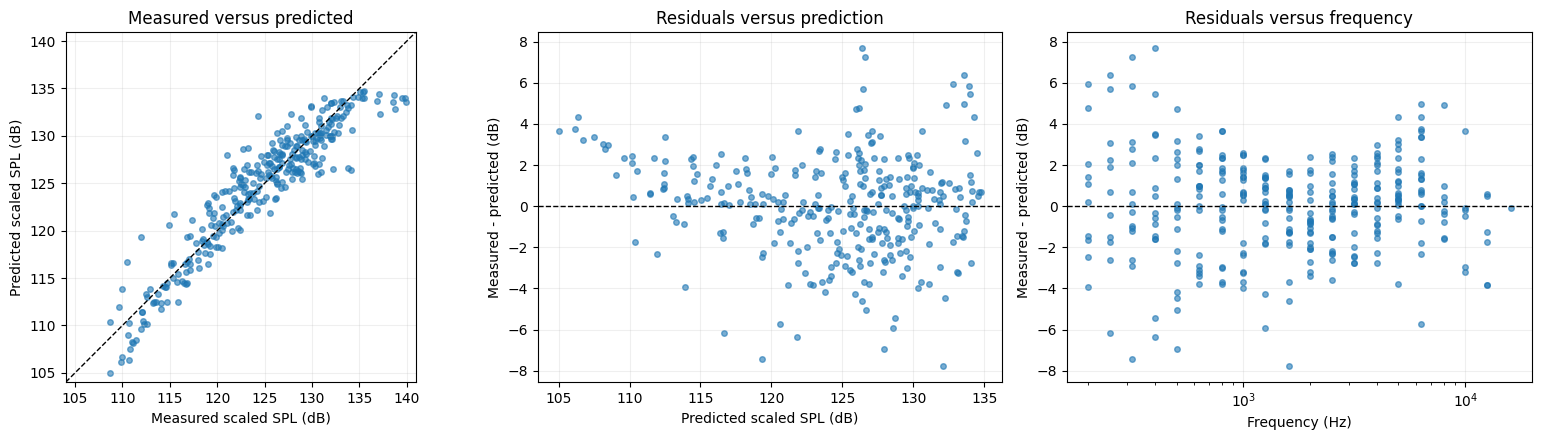

In [37]:
# Plot test predictions and residuals to inspect agreement and systematic error patterns.

actual = test_prediction_table["measured_spl_db"]
predicted = test_prediction_table["predicted_spl_db"]
residuals = test_prediction_table["residual_db"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

limits = [
    min(actual.min(), predicted.min()) - 1,
    max(actual.max(), predicted.max()) + 1,
]

axes[0].scatter(actual, predicted, s=16, alpha=0.6)
axes[0].plot(limits, limits, "k--", linewidth=1)
axes[0].set(
    xlabel="Measured scaled SPL (dB)",
    ylabel="Predicted scaled SPL (dB)",
    title="Measured versus predicted",
    xlim=limits,
    ylim=limits,
)
axes[0].set_aspect("equal", adjustable="box")

axes[1].scatter(predicted, residuals, s=16, alpha=0.6)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(
    xlabel="Predicted scaled SPL (dB)",
    ylabel="Measured - predicted (dB)",
    title="Residuals versus prediction",
)

axes[2].scatter(
    X_test["frequency_hz"],
    residuals,
    s=16,
    alpha=0.6,
)
axes[2].set_xscale("log")
axes[2].axhline(0, color="black", linestyle="--", linewidth=1)
axes[2].set(
    xlabel="Frequency (Hz)",
    ylabel="Measured - predicted (dB)",
    title="Residuals versus frequency",
)

for ax in axes:
    ax.grid(alpha=0.2)

fig.tight_layout()

fig.savefig(
    output_dir / "final_test_diagnostics.png",
    dpi=200,
)

plt.show()

In [38]:
# Save the model comparison, test metrics and individual predictions for the report.

selection_table.to_csv(
    output_dir / "model_selection_comparison.csv",
    index=False,
)

test_metrics.to_csv(
    output_dir / "final_test_metrics.csv",
    index=False,
)

test_prediction_table.to_csv(
    output_dir / "final_test_predictions.csv",
    index=False,
)

print("Evaluation results saved in:", output_dir.resolve())

Evaluation results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results


**Model selection and evaluation**

SVR with logarithmic preprocessing and standard scaling was selected because it achieved the lowest mean grouped cross-validation RMSE of **2.829 dB**. Its selected parameters were **C = 100, epsilon = 0.5 and gamma = 0.05**. On the reserved test data, it achieved **RMSE = 2.410 dB, MAE = 1.844 dB and R² = 0.876**, reducing RMSE by approximately **64.8%** compared with the mean baseline.

Predictions generally followed the measured values, with little overall signed bias (**mean residual = +0.042 dB**). However, the largest absolute error was **7.779 dB**, and eight of the ten largest errors occurred between **200–500 Hz**, showing uneven performance across operating conditions. These results support prediction for withheld groups within this dataset; they do not establish accuracy for other airfoil geometries or conditions outside the available data.



In [39]:
# Describe whether final-test inputs exceed the development feature ranges.

development_minimum = X_dev[FEATURES].min()
development_maximum = X_dev[FEATURES].max()

below_development = X_test[FEATURES].lt(
    development_minimum
)

above_development = X_test[FEATURES].gt(
    development_maximum
)

test_coverage = pd.DataFrame({
    "development_minimum": development_minimum,
    "development_maximum": development_maximum,
    "test_rows_below_minimum": below_development.sum(),
    "test_rows_above_maximum": above_development.sum()
})

outside_any_range = (
    below_development | above_development
).any(axis=1)

print(
    "Final-test rows outside at least one development range:",
    int(outside_any_range.sum()),
    "of",
    len(X_test)
)

test_coverage.to_csv(
    output_dir / "final_test_input_coverage.csv",
    index_label="feature"
)

test_coverage

Final-test rows outside at least one development range: 0 of 321


,development_minimum,development_maximum,test_rows_below_minimum,test_rows_above_maximum
frequency_hz,200.000000,20000.000000,0,0
angle_deg,0.000000,22.200000,0,0
chord_m,0.025400,0.304800,0,0
velocity_m_s,31.700000,71.300000,0,0
displacement_thickness_m,0.000401,0.058411,0,0


## Stage 7: Input Sensitivity Analysis

In [40]:
# Define input ranges, units, and perturbations of 1% and 5% of each range.

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

STEP_FRACTIONS = [0.01, 0.05]

FEATURE_UNITS = {
    "frequency_hz": "Hz",
    "angle_deg": "degrees",
    "chord_m": "m",
    "velocity_m_s": "m/s",
    "displacement_thickness_m": "m",
}

# Find the minimum and maximum of each development-data feature.
feature_ranges = pd.DataFrame({
    "minimum": X_dev[FEATURES].min(),
    "maximum": X_dev[FEATURES].max(),
})

# Calculate the observed range.
feature_ranges["range"] = (
    feature_ranges["maximum"] - feature_ranges["minimum"]
)

# Stop if a feature has no variation.
if (feature_ranges["range"] <= 0).any():
    raise ValueError(
        "Each feature must have a positive range for this analysis."
    )

# Attach the physical units to their matching features.
feature_ranges["unit"] = pd.Series(FEATURE_UNITS)

# Calculate both step sizes from the fractions defined above.
for fraction in STEP_FRACTIONS:
    column_name = f"step_{100 * fraction:g}_percent"

    feature_ranges[column_name] = (
        fraction * feature_ranges["range"]
    )

# Display the settings for the sensitivity analysis.
feature_ranges

,minimum,maximum,range,unit,step_1_percent,step_5_percent
frequency_hz,200.000000,20000.000000,19800.000000,Hz,198.000000,990.000000
angle_deg,0.000000,22.200000,22.200000,degrees,0.222000,1.110000
chord_m,0.025400,0.304800,0.279400,m,0.002794,0.013970
velocity_m_s,31.700000,71.300000,39.600000,m/s,0.396000,1.980000
displacement_thickness_m,0.000401,0.058411,0.058011,m,0.000580,0.002901


In [41]:
# Select reference rows that allow all perturbations to remain within observed input ranges.

margin = max(STEP_FRACTIONS) * feature_ranges["range"]

lower_limits = feature_ranges["minimum"] + margin
upper_limits = feature_ranges["maximum"] - margin

inside_limits = (
    X_dev[FEATURES].ge(lower_limits)
    & X_dev[FEATURES].le(upper_limits)
).all(axis=1)

X_sensitivity = X_dev.loc[inside_limits, FEATURES].copy()

if X_sensitivity.empty:
    raise ValueError(
        "No development rows satisfy the selected perturbation limits."
    )

reference_predictions = final_model.predict(X_sensitivity)

print("Development rows:", len(X_dev))
print("Sensitivity reference rows:", len(X_sensitivity))
print(
    "Percentage retained:",
    f"{100 * len(X_sensitivity) / len(X_dev):.1f}%",
)

Development rows: 1182
Sensitivity reference rows: 124
Percentage retained: 10.5%


In [42]:
# Define input changes equal to 1% and 5% of each development-data range.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

STEP_FRACTIONS = [0.01, 0.05]

FEATURE_UNITS = {
    "frequency_hz": "Hz",
    "angle_deg": "degrees",
    "chord_m": "m",
    "velocity_m_s": "m/s",
    "displacement_thickness_m": "m",
}

feature_ranges = pd.DataFrame(
    {
        "minimum": X_dev[FEATURES].min(),
        "maximum": X_dev[FEATURES].max(),
    }
)

feature_ranges["range"] = (
    feature_ranges["maximum"] - feature_ranges["minimum"]
)

if (feature_ranges["range"] <= 0).any():
    raise ValueError(
        "Each feature must have a positive range for this analysis."
    )

feature_ranges["unit"] = pd.Series(FEATURE_UNITS)

feature_ranges["step_1_percent"] = (
    0.01 * feature_ranges["range"]
)

feature_ranges["step_5_percent"] = (
    0.05 * feature_ranges["range"]
)

feature_ranges

,minimum,maximum,range,unit,step_1_percent,step_5_percent
frequency_hz,200.000000,20000.000000,19800.000000,Hz,198.000000,990.000000
angle_deg,0.000000,22.200000,22.200000,degrees,0.222000,1.110000
chord_m,0.025400,0.304800,0.279400,m,0.002794,0.013970
velocity_m_s,31.700000,71.300000,39.600000,m/s,0.396000,1.980000
displacement_thickness_m,0.000401,0.058411,0.058011,m,0.000580,0.002901


In [43]:
# Measure prediction changes when each input is increased and decreased separately.

sensitivity_rows = []

for feature in FEATURES:
    for fraction in STEP_FRACTIONS:
        step = fraction * feature_ranges.loc[feature, "range"]

        X_plus = X_sensitivity.copy()
        X_minus = X_sensitivity.copy()

        X_plus[feature] = X_plus[feature] + step
        X_minus[feature] = X_minus[feature] - step

        predictions_plus = final_model.predict(X_plus)
        predictions_minus = final_model.predict(X_minus)

        changes = np.concatenate(
            [
                predictions_plus - reference_predictions,
                predictions_minus - reference_predictions,
            ]
        )

        absolute_changes = np.abs(changes)

        sensitivity_rows.append(
            {
                "feature": feature,
                "step_percent_of_range": 100 * fraction,
                "step_size": step,
                "n_reference_rows": len(X_sensitivity),
                "mean_abs_change_db": absolute_changes.mean(),
                "p95_abs_change_db": np.percentile(
                    absolute_changes, 95
                ),
                "max_abs_change_db": absolute_changes.max(),
            }
        )

sensitivity_results = pd.DataFrame(sensitivity_rows)

sensitivity_results.round(4)

,feature,step_percent_of_range,step_size,n_reference_rows,mean_abs_change_db,p95_abs_change_db,max_abs_change_db
0,frequency_hz,1.0,198.0000,124,0.6095,1.1163,1.4035
1,frequency_hz,5.0,990.0000,124,3.0238,5.5704,10.6248
2,angle_deg,1.0,0.2220,124,0.2018,0.2706,0.2794
3,angle_deg,5.0,1.1100,124,1.0065,1.3435,1.4177
4,chord_m,1.0,0.0028,124,0.2453,0.6143,0.7126
5,chord_m,5.0,0.0140,124,1.2392,3.0210,4.0507
6,velocity_m_s,1.0,0.3960,124,0.0671,0.0983,0.1163
7,velocity_m_s,5.0,1.9800,124,0.3353,0.4909,0.5867
8,displacement_thickness_m,1.0,0.0006,124,0.1471,0.4549,0.7363
9,displacement_thickness_m,5.0,0.0029,124,0.8496,3.0728,6.5556


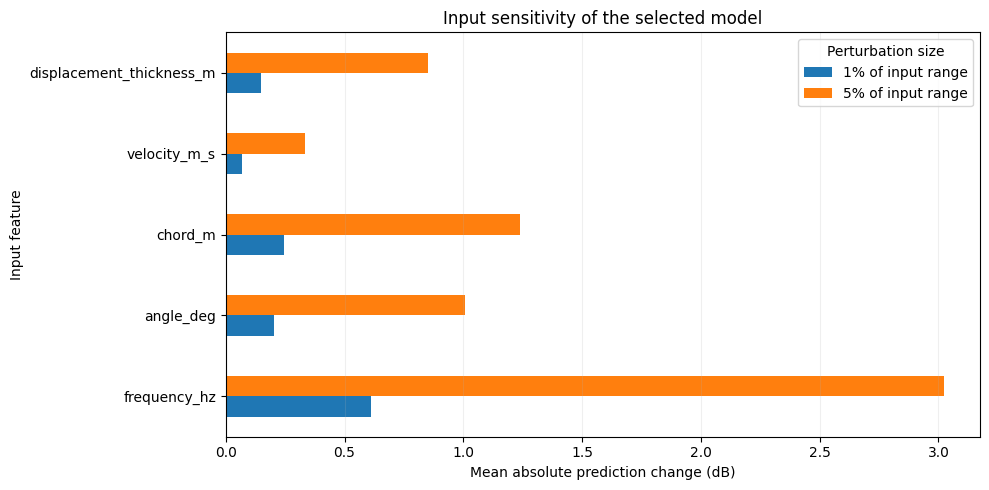

In [44]:
# Compare average prediction sensitivity across inputs and perturbation sizes.

sensitivity_plot_data = sensitivity_results.pivot(
    index="feature",
    columns="step_percent_of_range",
    values="mean_abs_change_db",
)

sensitivity_plot_data = sensitivity_plot_data.reindex(FEATURES)

sensitivity_plot_data.columns = [
    f"{value:g}% of input range"
    for value in sensitivity_plot_data.columns
]

fig, ax = plt.subplots(figsize=(10, 5))

sensitivity_plot_data.plot(
    kind="barh",
    ax=ax,
)

ax.set_xlabel("Mean absolute prediction change (dB)")
ax.set_ylabel("Input feature")
ax.set_title("Input sensitivity of the selected model")

ax.grid(axis="x", alpha=0.2)
ax.legend(title="Perturbation size")

fig.tight_layout()

fig.savefig(
    output_dir / "input_sensitivity.png",
    dpi=200,
)

plt.show()

In [45]:
# Save the sensitivity results, perturbation settings and reference observations.

sensitivity_results.to_csv(
    output_dir / "input_sensitivity_results.csv",
    index=False,
)

feature_ranges.to_csv(
    output_dir / "input_sensitivity_settings.csv",
    index_label="feature",
)

X_sensitivity.to_csv(
    output_dir / "input_sensitivity_reference_inputs.csv",
    index_label="row_index",
)

print("Sensitivity results saved in:", output_dir.resolve())

Sensitivity results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results


In [46]:
# Test how changing one training target affects predictions after refitting.

target_shift_db = 5.0

perturbation_models = {
    "Linear": models["Linear"],
    "Selected_SVR": final_model
}

perturbation_rows = []
# Choose one training-row position per fold, shared by both models.
target_rng = np.random.default_rng(SEED)

changed_positions = {
    fold_number: int(target_rng.integers(len(train_rows)))
    for fold_number, (train_rows, _) in enumerate(folds, start=1)
}

# Fit and compare clean and perturbed models within each fold.
for model_name, model_template in perturbation_models.items():
    for fold_number, (train_rows, validation_rows) in enumerate(
        folds,
        start=1
    ):
        X_training = X_dev.iloc[train_rows]
        y_training = y_dev.iloc[train_rows].copy()

        X_validation = X_dev.iloc[validation_rows]
        y_validation = y_dev.iloc[validation_rows]

        # Fit a clean reference using this fold's training rows.
        clean_model = clone(model_template).fit(
            X_training,
            y_training
        )

        clean_predictions = clean_model.predict(
            X_validation
        )

        # Change the selected training target in a separate copy.
        changed_position = changed_positions[fold_number]

        changed_targets = y_training.copy()
        changed_targets.iloc[changed_position] += target_shift_db

        changed_model = clone(model_template).fit(
            X_training,
            changed_targets
        )

        changed_predictions = changed_model.predict(
            X_validation
        )

        prediction_change = (
            changed_predictions - clean_predictions
        )

        perturbation_rows.append({
            "model": model_name,
            "fold": fold_number,
            "changed_row_index": y_training.index[changed_position],
            "target_shift_db": target_shift_db,
            "clean_rmse_db": np.sqrt(
                mean_squared_error(
                    y_validation,
                    clean_predictions
                )
            ),
            "changed_rmse_db": np.sqrt(
                mean_squared_error(
                    y_validation,
                    changed_predictions
                )
            ),
            "mean_abs_prediction_change_db": np.mean(
                np.abs(prediction_change)
            ),
            "max_abs_prediction_change_db": np.max(
                np.abs(prediction_change)
            )
        })

training_perturbation_results = pd.DataFrame(
    perturbation_rows
)

training_perturbation_summary = (
    training_perturbation_results
    .groupby("model")
    .agg(
        mean_clean_rmse_db=("clean_rmse_db", "mean"),
        mean_changed_rmse_db=("changed_rmse_db", "mean"),
        mean_abs_prediction_change_db=(
            "mean_abs_prediction_change_db",
            "mean"
        ),
        largest_prediction_change_db=(
            "max_abs_prediction_change_db",
            "max"
        )
    )
)

training_perturbation_results.to_csv(
    output_dir / "training_observation_sensitivity.csv",
    index=False
)

training_perturbation_summary.to_csv(
    output_dir / "training_observation_sensitivity_summary.csv"
)

training_perturbation_summary.round(4)

,mean_clean_rmse_db,mean_changed_rmse_db,mean_abs_prediction_change_db,largest_prediction_change_db
model,,,,
Linear,4.7281,4.7283,0.0091,0.0380
Selected_SVR,2.8290,2.8287,0.0222,0.2699


## Stage 8: runtime profiling and computational optimisation.

In [47]:
# Set up a repeatable benchmark using development inputs and fixed timing settings.
output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

N_REPEATS = 5
PREDICT_CALLS = 10

X_timing = X_dev.sample(
    n=min(200, len(X_dev)),
    random_state=SEED,
).copy()

print("Training observations:", len(X_dev))
print("Prediction observations per batch:", len(X_timing))
print("Timing repetitions:", N_REPEATS)

Training observations: 1182
Prediction observations per batch: 200
Timing repetitions: 5


In [48]:
# Measure repeated training times and average batch-prediction times for one configuration.

def benchmark_model(
    estimator,
    train_X,
    train_y,
    predict_X,
    repeats=5,
    predict_calls=10,
):
    """
    Benchmark an estimator using development training data and prediction inputs.

    Returns one row per repetition containing fitting time in seconds
    and average prediction time per batch in milliseconds.
    """
    rows = []

    with threadpool_limits(limits=1):
        warm_model = clone(estimator).fit(train_X, train_y)
        warm_model.predict(predict_X)

        for repeat in range(repeats):
            fitted = clone(estimator)

            start = perf_counter()
            fitted.fit(train_X, train_y)
            fit_time = perf_counter() - start

            fitted.predict(predict_X)

            start = perf_counter()

            for _ in range(predict_calls):
                fitted.predict(predict_X)

            predict_time = (
                perf_counter() - start
            ) / predict_calls

            rows.append(
                {
                    "repeat": repeat + 1,
                    "fit_time_s": fit_time,
                    "predict_time_ms": 1000 * predict_time,
                }
            )

    return pd.DataFrame(rows)

In [49]:
# Compare the tuned candidates using identical timing inputs and settings.

# Retrieve each candidate's tuned pipeline.
# benchmark_model clones these pipelines before fitting them.
runtime_candidates = {
    name: search.best_estimator_
    for name, search in candidate_searches.items()
}

runtime_tables = []

for name, estimator in runtime_candidates.items():
    table = benchmark_model(
        estimator,
        X_dev,
        y_dev,
        X_timing,
        repeats=N_REPEATS,
        predict_calls=PREDICT_CALLS,
    )

    # Record which tuned candidate produced these measurements.
    table.insert(0, "candidate", name)
    runtime_tables.append(table)

# Combine the individual timing measurements.
runtime_raw = pd.concat(
    runtime_tables,
    ignore_index=True,
)

# Summarise repeated measurements using their median.
runtime_summary = runtime_raw.groupby("candidate").agg(
    fit_median_s=("fit_time_s", "median"),
    predict_median_ms=("predict_time_ms", "median"),
)

# Attach the CV error belonging to the same tuned configuration.
runtime_summary = runtime_summary.join(
    selection_table.set_index("candidate")[["cv_rmse_db"]]
)

runtime_summary.round(4)

,fit_median_s,predict_median_ms,cv_rmse_db
candidate,,,
Ridge_log_scaled,0.0061,3.0394,5.2171
Ridge_scaled,0.0038,1.0374,4.7273
SVR_log_scaled,0.0969,19.2323,2.8290
SVR_scaled,0.2037,16.4154,3.4767


In [50]:
# Verify that individual and batch prediction give equivalent results.

def predict_one_at_a_time(model, inputs):
    """Predict each observation separately and return a 1D array."""
    return np.array([
        # Double brackets preserve the dataframe format and column names.
        model.predict(inputs.iloc[[i]])[0]
        for i in range(len(inputs))
    ])


def predict_in_batch(model, inputs):
    """Predict all observations together and return a 1D array."""
    return model.predict(inputs)


# Apply the same thread-pool limit to both prediction workflows.
with threadpool_limits(limits=1):
    individual_predictions = predict_one_at_a_time(
        final_model,
        X_timing,
    )

    batch_predictions = predict_in_batch(
        final_model,
        X_timing,
    )

# Stop this cell if any prediction differs by more than 1e-10 dB.
np.testing.assert_allclose(
    individual_predictions,
    batch_predictions,
    rtol=0,
    atol=1e-10,
)

# Record the largest absolute difference for the benchmark report.
max_prediction_difference = float(
    np.max(
        np.abs(
            individual_predictions - batch_predictions
        )
    )
)

print("Number of observations checked:", len(X_timing))
print(
    "Maximum prediction difference:",
    f"{max_prediction_difference:.3e}",
    "dB",
)
print("Prediction-equivalence check passed.")

Number of observations checked: 200
Maximum prediction difference: 0.000e+00 dB
Prediction-equivalence check passed.


In [51]:
# Compare repeated timings for individual and batch prediction on the same inputs.

prediction_functions = {
    "one_at_a_time": predict_one_at_a_time,
    "batch": predict_in_batch,
}

batch_timing_rows = []

with threadpool_limits(limits=1):
    for repeat in range(N_REPEATS):
        methods = list(prediction_functions.items())

        if repeat % 2 == 1:
            methods.reverse()

        for method_name, function in methods:
            start = perf_counter()

            function(final_model, X_timing)

            elapsed = perf_counter() - start

            batch_timing_rows.append(
                {
                    "repeat": repeat + 1,
                    "method": method_name,
                    "time_ms": 1000 * elapsed,
                }
            )

batch_timing_raw = pd.DataFrame(batch_timing_rows)

batch_summary = batch_timing_raw.groupby("method").agg(
    median_time_ms=("time_ms", "median"),
    minimum_time_ms=("time_ms", "min"),
    maximum_time_ms=("time_ms", "max"),
)

speedup = (
    batch_summary.loc["one_at_a_time", "median_time_ms"]
    / batch_summary.loc["batch", "median_time_ms"]
)

print(f"Batch prediction speedup: {speedup:.2f} times")

batch_summary.round(3)

Batch prediction speedup: 38.81 times


,median_time_ms,minimum_time_ms,maximum_time_ms
method,,,
batch,17.955,16.327,19.881
one_at_a_time,696.893,685.713,757.151


In [52]:
# Profile function calls in both prediction workflows to investigate runtime overhead.

profiles = {}
profile_reports = {}

with threadpool_limits(limits=1):
    for method_name, function in prediction_functions.items():
        profiler = cProfile.Profile()

        profiler.runcall(
            function,
            final_model,
            X_timing,
        )

        report_stream = io.StringIO()

        stats = pstats.Stats(
            profiler,
            stream=report_stream,
        )

        stats.strip_dirs().sort_stats(
            "cumulative"
        ).print_stats(15)

        profiles[method_name] = profiler
        profile_reports[method_name] = report_stream.getvalue()

        print(f"\nProfile: {method_name}")
        print(profile_reports[method_name])


Profile: one_at_a_time
         1292729 function calls (1266127 primitive calls) in 1.464 seconds

   Ordered by: cumulative time
   List reduced from 645 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      200    0.003    0.000    1.380    0.007 pipeline.py:746(predict)
        1    0.003    0.003    1.286    1.286 4106489718.py:3(predict_one_at_a_time)
  800/400    0.004    0.000    1.245    0.003 _set_output.py:325(wrapped)
      200    0.009    0.000    1.148    0.006 _column_transformer.py:1009(transform)
      200    0.006    0.000    0.926    0.005 _column_transformer.py:815(_call_func_on_transformers)
      600    0.006    0.000    0.503    0.001 validation.py:2932(validate_data)
      200    0.001    0.000    0.470    0.002 parallel.py:54(__call__)
      200    0.003    0.000    0.468    0.002 parallel.py:1995(__call__)
      800    0.003    0.000    0.458    0.001 parallel.py:1914(_get_sequential_output)
      400    0

In [53]:
# Save timing measurements, profiler output and environment details for reproducibility.

runtime_raw.to_csv(
    output_dir / "runtime_raw.csv",
    index=False,
)

runtime_summary.to_csv(
    output_dir / "runtime_summary.csv",
)

batch_timing_raw.to_csv(
    output_dir / "batch_timing_raw.csv",
    index=False,
)

batch_summary.to_csv(
    output_dir / "batch_timing_summary.csv",
)

for method_name, profiler in profiles.items():
    profiler.dump_stats(
        str(output_dir / f"prediction_{method_name}.prof")
    )

    (output_dir / f"prediction_{method_name}_profile.txt").write_text(
        profile_reports[method_name],
        encoding="utf-8",
    )

benchmark_details = {
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "operating_system": platform.platform(),
    "processor": platform.processor() or "Not reported",
    "logical_cpu_count": os.cpu_count(),
    "supported_threadpool_limit": 1,
    "training_rows": len(X_dev),
    "prediction_rows": len(X_timing),
    "timing_repetitions": N_REPEATS,
    "prediction_calls_per_runtime_repetition": PREDICT_CALLS,
    "batch_speedup": float(speedup),
    "maximum_prediction_difference_db": float(
        max_prediction_difference
    ),
}

with (output_dir / "benchmark_details.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(benchmark_details, file, indent=2)

print("Performance results saved in:", output_dir.resolve())

Performance results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results


## Stage 9: Save slected model and create reusable prediction function 

In [54]:
# Record the input units, supported ranges and software versions.
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

feature_units = {
    "frequency_hz": "Hz",
    "angle_deg": "degrees",
    "chord_m": "m",
    "velocity_m_s": "m/s",
    "displacement_thickness_m": "m"
}

positive_features = [
    "frequency_hz",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m"
]

model_metadata = {
    "selected_candidate": selected_name,
    "features": FEATURES.copy(),
    "target": TARGET,
    "target_unit": "dB",
    "feature_units": feature_units,
    "positive_features": positive_features,
    "input_minimum": X_dev[FEATURES].min().to_dict(),
    "input_maximum": X_dev[FEATURES].max().to_dict(),
    "training_rows": len(X_dev),
        "range_basis": "Per-feature minimum and maximum of development inputs",
    "range_policy": "Reject inputs outside the recorded development ranges",
    "range_limitation": (
        "Being inside each feature range does not guarantee that the "
        "combination was represented in training or that predictions are accurate."
    ),
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__,
        "joblib": joblib.__version__
    }
}

input_requirements = pd.DataFrame({
    "unit": pd.Series(feature_units),
    "minimum": pd.Series(model_metadata["input_minimum"]),
    "maximum": pd.Series(model_metadata["input_maximum"])
})

input_requirements

,unit,minimum,maximum
frequency_hz,Hz,200.000000,20000.000000
angle_deg,degrees,0.000000,22.200000
chord_m,m,0.025400,0.304800
velocity_m_s,m/s,31.700000,71.300000
displacement_thickness_m,m,0.000401,0.058411


In [55]:
# Save the fitted pipeline together with its input requirements.

model_bundle = {
    "pipeline": final_model,
    "metadata": model_metadata
}

model_path = model_dir / "final_airfoil_model.joblib"
metadata_path = model_dir / "final_airfoil_metadata.json"

joblib.dump(model_bundle, model_path, compress=3)

with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(model_metadata, file, indent=2)

print("Saved model:", model_path)
print("Saved metadata:", metadata_path)

Saved model: models\final_airfoil_model.joblib
Saved metadata: models\final_airfoil_metadata.json


In [56]:
# Reload the saved model to check that it can be reused.

loaded_bundle = joblib.load(model_path)

print(
    "Loaded candidate:",
    loaded_bundle["metadata"]["selected_candidate"]
)

print(
    "Required inputs:",
    loaded_bundle["metadata"]["features"]
)

Loaded candidate: SVR_log_scaled
Required inputs: ['frequency_hz', 'angle_deg', 'chord_m', 'velocity_m_s', 'displacement_thickness_m']


In [60]:
# Demonstrate noise prediction using five existing development observations.

# Use known inputs that satisfy the recorded development-range limits.
noise_inputs = X_dev[FEATURES].head(5).copy()

# Predict scaled sound pressure level using the saved model.
noise_predictions = predict_airfoil(
    noise_inputs,
    loaded_bundle,
)

# Display the input conditions beside measured and predicted noise levels.
noise_results = noise_inputs.copy()

noise_results["measured_scaled_spl_db"] = y_dev.loc[
    noise_inputs.index
]

noise_results["predicted_scaled_spl_db"] = noise_predictions

noise_results["residual_db"] = (
    noise_results["measured_scaled_spl_db"]
    - noise_results["predicted_scaled_spl_db"]
)

noise_results.round(3)

,frequency_hz,angle_deg,chord_m,velocity_m_s,displacement_thickness_m,measured_scaled_spl_db,predicted_scaled_spl_db,residual_db
0,800,0.0,0.305,71.3,0.003,126.201,125.943,0.258
1,1000,0.0,0.305,71.3,0.003,125.201,126.511,-1.310
2,1250,0.0,0.305,71.3,0.003,125.951,126.726,-0.775
3,1600,0.0,0.305,71.3,0.003,127.591,126.559,1.032
4,2000,0.0,0.305,71.3,0.003,127.461,126.060,1.401


In [57]:
# Check prediction equivalence, column ordering and output row alignment.

example_inputs = X_dev[FEATURES].head(5).copy()

example_predictions = predict_airfoil(
    example_inputs,
    loaded_bundle
)

original_predictions = final_model.predict(example_inputs)

np.testing.assert_allclose(
    example_predictions.to_numpy(),
    original_predictions,
    rtol=0,
    atol=1e-10
)

reordered_predictions = predict_airfoil(
    example_inputs.loc[:, FEATURES[::-1]],
    loaded_bundle
)

np.testing.assert_allclose(
    reordered_predictions.to_numpy(),
    example_predictions.to_numpy(),
    rtol=0,
    atol=1e-10
)

assert example_predictions.index.equals(example_inputs.index)

print("PASS: saved and original predictions match.")
print("PASS: changing column order preserves predictions.")
print("PASS: predictions preserve the input row index.")

prediction_example = example_inputs.copy()

prediction_example["predicted_scaled_spl_db"] = example_predictions

prediction_example

PASS: saved and original predictions match.
PASS: changing column order preserves predictions.
PASS: predictions preserve the input row index.


,frequency_hz,angle_deg,chord_m,velocity_m_s,displacement_thickness_m,predicted_scaled_spl_db
0,800,0.0,0.3048,71.3,0.002663,125.943109
1,1000,0.0,0.3048,71.3,0.002663,126.511270
2,1250,0.0,0.3048,71.3,0.002663,126.725610
3,1600,0.0,0.3048,71.3,0.002663,126.559452
4,2000,0.0,0.3048,71.3,0.002663,126.060264


In [58]:
# Test common invalid inputs and record whether they are rejected correctly.

invalid_cases = {
    "Wrong container": (
        example_inputs.to_numpy(),
        TypeError
    ),
    "Empty input": (
        example_inputs.iloc[:0],
        ValueError
    ),
    "Missing column": (
        example_inputs.drop(columns=["frequency_hz"]),
        ValueError
    ),
    "Extra column": (
        example_inputs.assign(unexpected_column=1),
        ValueError
    ),
    "Duplicate column": (
        pd.concat(
            [example_inputs, example_inputs[["frequency_hz"]]],
            axis=1
        ),
        ValueError
    ),
    "Text input": (
        example_inputs.assign(frequency_hz="invalid"),
        TypeError
    ),
    "Missing value": (
        example_inputs.assign(frequency_hz=np.nan),
        ValueError
    ),
    "Infinite value": (
        example_inputs.assign(frequency_hz=np.inf),
        ValueError
    ),
    "Zero frequency": (
        example_inputs.assign(frequency_hz=0),
        ValueError
    ),
    "Outside supported range": (
        example_inputs.assign(
            velocity_m_s=(
                loaded_bundle["metadata"]["input_maximum"]
                ["velocity_m_s"] + 1
            )
        ),
        ValueError
    )
}

verification_rows = []

for test_name, (invalid_input, expected_error) in invalid_cases.items():
    try:
        predict_airfoil(invalid_input, loaded_bundle)

    except expected_error as error:
        verification_rows.append({
            "test": test_name,
            "status": "PASS",
            "message": str(error)
        })

    else:
        verification_rows.append({
            "test": test_name,
            "status": "FAIL",
            "message": "Invalid input was accepted."
        })

verification_report = pd.DataFrame(verification_rows)

verification_report.to_csv(
    output_dir / "prediction_verification.csv",
    index=False
)

prediction_example.to_csv(
    output_dir / "prediction_example.csv",
    index_label="row_index"
)

if (verification_report["status"] != "PASS").any():
    raise AssertionError(
        "An input validation check failed. Inspect verification_report."
    )

verification_report

,test,status,message
0,Wrong container,PASS,Inputs must be a pandas DataFrame.
1,Empty input,PASS,Provide at least one input row.
2,Missing column,PASS,Column mismatch. Missing: ['frequency_hz']; ex...
3,Extra column,PASS,Column mismatch. Missing: []; extra: ['unexpec...
4,Duplicate column,PASS,Duplicate column names are not supported.
5,Text input,PASS,frequency_hz must contain real numeric values.
6,Missing value,PASS,Missing input values are not supported.
7,Infinite value,PASS,Infinite input values are not supported.
8,Zero frequency,PASS,"Frequency, chord, velocity and thickness must ..."
9,Outside supported range,PASS,Inputs outside supported development ranges: [...


In [59]:
# Save five development observations as an example prediction input file.

from pathlib import Path
import sys

example_dir = Path("examples")
example_dir.mkdir(exist_ok=True)

prediction_inputs = X_dev[FEATURES].head(5).copy()

prediction_inputs.to_csv(
    example_dir / "prediction_inputs.csv",
    index=False
)

print("Project working folder:", Path.cwd())
print("Notebook Python:", sys.executable)
print("Saved example input: examples/prediction_inputs.csv")

prediction_inputs

Project working folder: c:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project
Notebook Python: C:\Users\zhihe\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe
Saved example input: examples/prediction_inputs.csv


,frequency_hz,angle_deg,chord_m,velocity_m_s,displacement_thickness_m
0,800,0.0,0.3048,71.3,0.002663
1,1000,0.0,0.3048,71.3,0.002663
2,1250,0.0,0.3048,71.3,0.002663
3,1600,0.0,0.3048,71.3,0.002663
4,2000,0.0,0.3048,71.3,0.002663


In [61]:
input_requirements

,unit,minimum,maximum
frequency_hz,Hz,200.000000,20000.000000
angle_deg,degrees,0.000000,22.200000
chord_m,m,0.025400,0.304800
velocity_m_s,m/s,31.700000,71.300000
displacement_thickness_m,m,0.000401,0.058411
